# Clustering Methods Exercises

![Clustering.png](Assets/Clustering.png)

# Цели обучения

- Обсудить алгоритмы обучения без учителя и способы их применения
- Применять кластеризацию
- Применять снижение размерности


## Введение

Для этих упражнений мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические характеристики вина, такие как кислотность, содержание сахара, pH и содержание алкоголя. Он также содержит показатель качества (от 3 до 9, где более высокое значение означает лучшее качество) и цвет (красное или белое). Имя файла — `Wine_Quality_Data`.

Мы будем использовать химические свойства (то есть все, кроме показателя качества и цвета) для кластеризации вин. Хотя это обучение без учителя, может быть интересно посмотреть, как результаты нашей кластеризации соотносятся с цветом и качеством.

In [60]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedShuffleSplit

from scipy.cluster.hierarchy import linkage, dendrogram

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Вопрос 1

* Импортируйте данные и проанализируйте характеристики.
* Определите, какие из них являются непрерывными, категориальными и булевыми.
* Сколько записей имеется для двух цветов вина и диапазона показателей качества?
* Постройте гистограмму показателя качества для каждого из цветов вина.

Типы данных для каждой записи. Реализация алгоритма K-means в библиотеке Scikit-learn рассчитана исключительно на работу с непрерывными данными (хотя иногда её применяют и для категориальных или булевых типов). К счастью, все столбцы, которые мы будем использовать (все, кроме «quality» и «color»), являются непрерывными.

In [45]:
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])

data = pd.read_csv(filepath)


print(data.shape)

data.head().T


(6497, 13)


,0,1,2,3,4
fixed_acidity,7.4,7.8,7.8,11.2,7.4
volatile_acidity,0.7,0.88,0.76,0.28,0.7
citric_acid,0.0,0.0,0.04,0.56,0.0
residual_sugar,1.9,2.6,2.3,1.9,1.9
chlorides,0.076,0.098,0.092,0.075,0.076
free_sulfur_dioxide,11.0,25.0,15.0,17.0,11.0
total_sulfur_dioxide,34.0,67.0,54.0,60.0,34.0
density,0.9978,0.9968,0.997,0.998,0.9978
pH,3.51,3.2,3.26,3.16,3.51
sulphates,0.56,0.68,0.65,0.58,0.56


In [46]:
print(data.dtypes)

print(data['color'].value_counts(), '\n')
print(data['quality'].value_counts().sort_index(), '\n')
print('Диапазон качества:', data['quality'].min(), '-', data['quality'].max(), '\n')
pd.crosstab(data['quality'], data['color'])


fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object
color
white    4898
red      1599
Name: count, dtype: int64 

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64 

Диапазон качества: 3 - 9 



color,red,white
quality,,
3,10,20
4,53,163
5,681,1457
6,638,2198
7,199,880
8,18,175
9,0,5


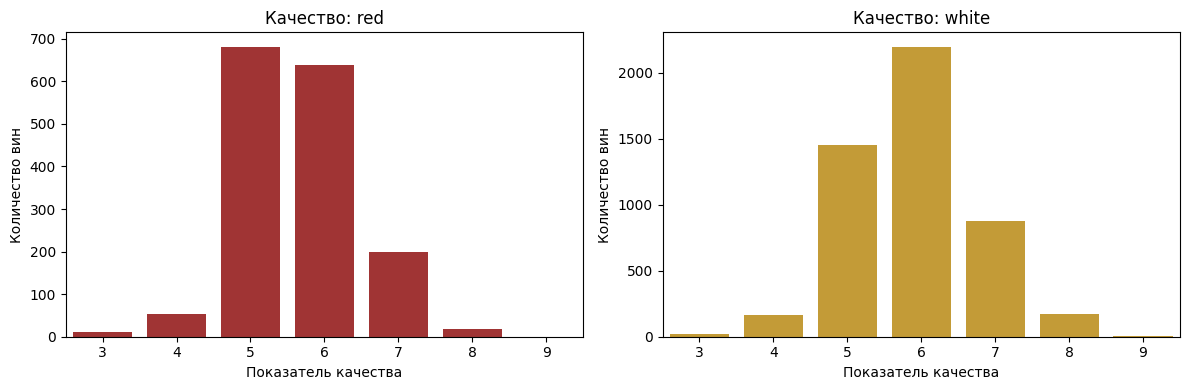

In [47]:
order = sorted(data['quality'].unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, (color, c) in zip(axes, [('red', 'firebrick'), ('white', 'goldenrod')]):
    sns.countplot(x='quality', data=data[data['color'] == color], order=order, color=c, ax=ax)
    ax.set_title('Качество: ' + color)
    ax.set_xlabel('Показатель качества')
    ax.set_ylabel('Количество вин')
plt.tight_layout()
plt.show()

## Вопрос 2

* Оцените корреляцию и асимметрию соответствующих переменных — всех, кроме цвета и качества.
* Проведите необходимые преобразования признаков и/или масштабирование.
* Проанализируйте парное распределение переменных с помощью парных графиков, чтобы проверить правильность масштабирования и нормализации.


А также анализ значений асимметрии в преддверии преобразований.

['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol']


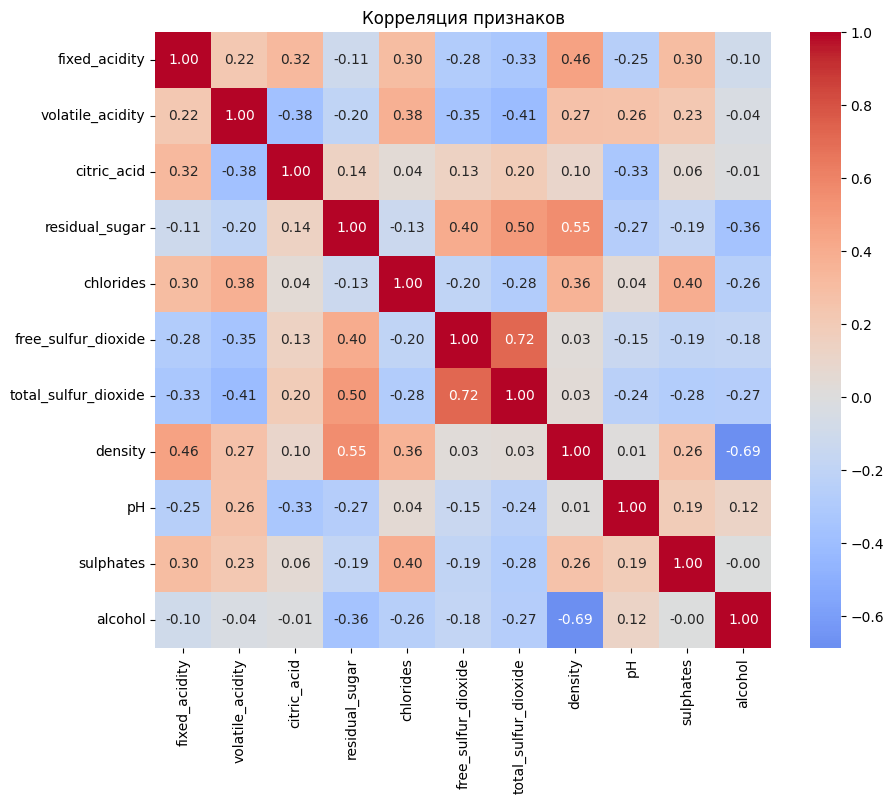

In [ ]:
float_columns = [x for x in data.columns if x not in ['color', 'quality']]
print(float_columns)

corr_mat = data[float_columns].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Корреляция признаков')
plt.show()

chlorides               5.399828
sulphates               1.797270
fixed_acidity           1.723290
volatile_acidity        1.495097
residual_sugar          1.435404
free_sulfur_dioxide     1.220066
alcohol                 0.565718
density                 0.503602
citric_acid             0.471731
pH                      0.386839
total_sulfur_dioxide   -0.001177
dtype: float64


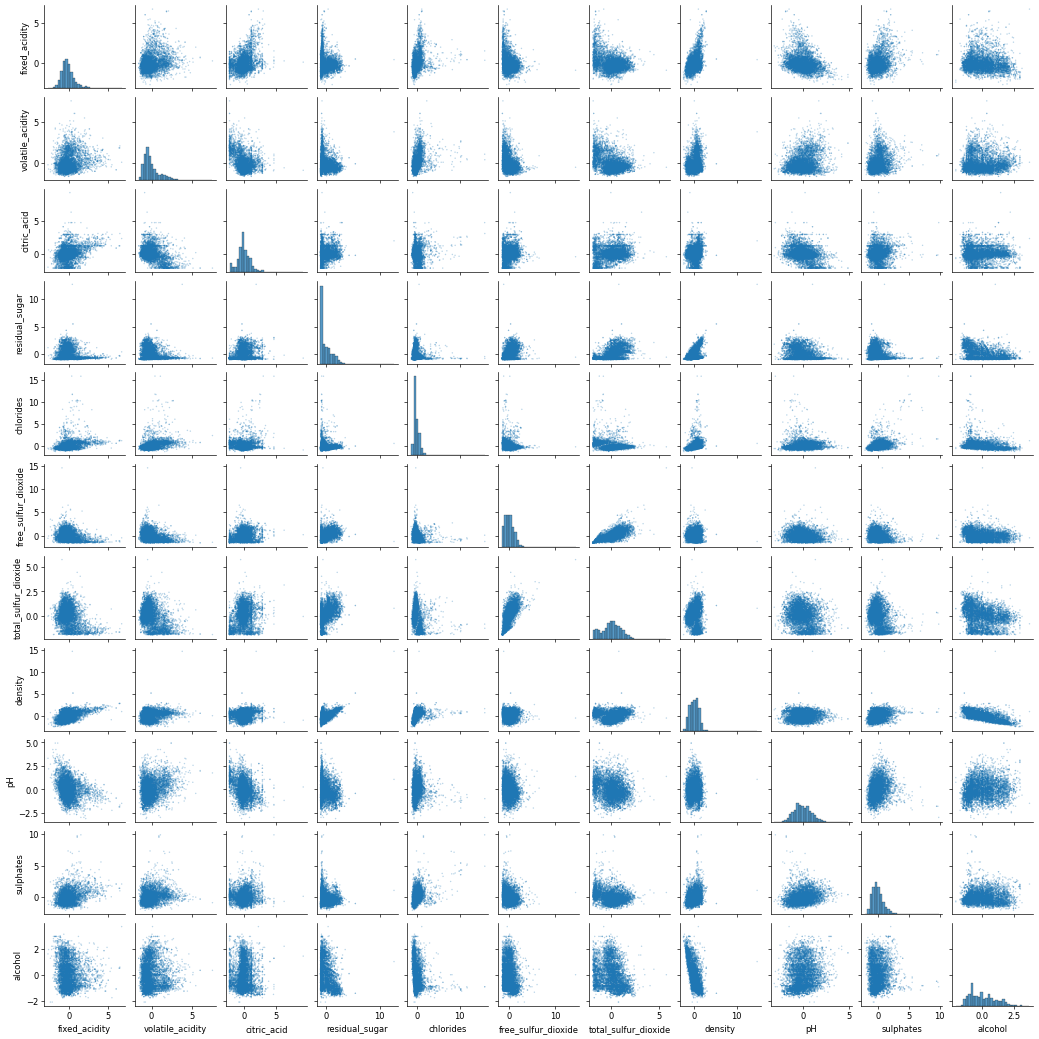

In [49]:
skew_columns = data[float_columns].skew().sort_values(ascending=False)
print(skew_columns)

skew_columns[skew_columns.abs() > 0.75]



scaler = StandardScaler()
data[float_columns] = scaler.fit_transform(data[float_columns])

data[float_columns].describe().loc[['mean', 'std', 'min', 'max']].round(2)


g = sns.pairplot(data[float_columns], diag_kind='hist', height=1.6,
                 plot_kws=dict(s=3, alpha=0.3, edgecolor='none'), diag_kws=dict(bins=30))
g.figure.set_dpi(60)
plt.show()

## Вопрос 3

* Постройте модель кластеризации методом K-средних с двумя кластерами.
* Проанализируйте кластеры по цвету вина.

kmeans     0     1
color             
red       24  1575
white   4831    67 

Доля каждого цвета по кластерам:
color     red  white
kmeans              
0       0.005  0.995
1       0.959  0.041


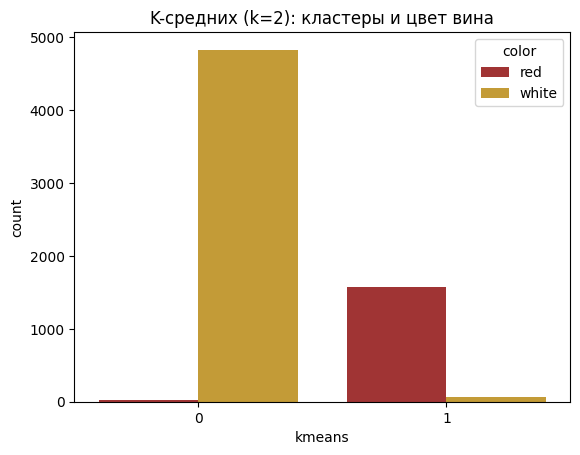

In [50]:
km = KMeans(n_clusters=2, n_init=10, random_state=42)
km = km.fit(data[float_columns])
data['kmeans'] = km.predict(data[float_columns])


print(data.groupby(['color', 'kmeans']).size().unstack(fill_value=0), '\n')
print('Доля каждого цвета по кластерам:')
print(pd.crosstab(data['kmeans'], data['color'], normalize='index').round(3))

sns.countplot(x='kmeans', hue='color', data=data, palette={'red': 'firebrick', 'white': 'goldenrod'})
plt.title('K-средних (k=2): кластеры и цвет вина')
plt.show()

## Вопрос 4

* Теперь постройте модели K-Means с количеством кластеров от 1 до 20.
* Для каждой модели запишите количество кластеров и значение инерции.
* Постройте график зависимости количества кластеров от инерции. Можно ли выделить какое-то идеальное количество кластеров?

In [51]:
ks = list(range(1, 21))
inertia = []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(data[float_columns])
    inertia.append(m.inertia_)

inertia_df = pd.DataFrame({'n_clusters': ks, 'inertia': inertia})
inertia_df['drop'] = inertia_df['inertia'].diff().round(0)
inertia_df

,n_clusters,inertia,drop
0,1,71467.000000,NaN
1,2,56143.929088,-15323.0
2,3,45576.999580,-10567.0
3,4,40721.014237,-4856.0
4,5,38069.168596,-2652.0
5,6,35831.176033,-2238.0
6,7,34054.073482,-1777.0
7,8,32898.153221,-1156.0
8,9,31667.111378,-1231.0
9,10,30589.556299,-1078.0


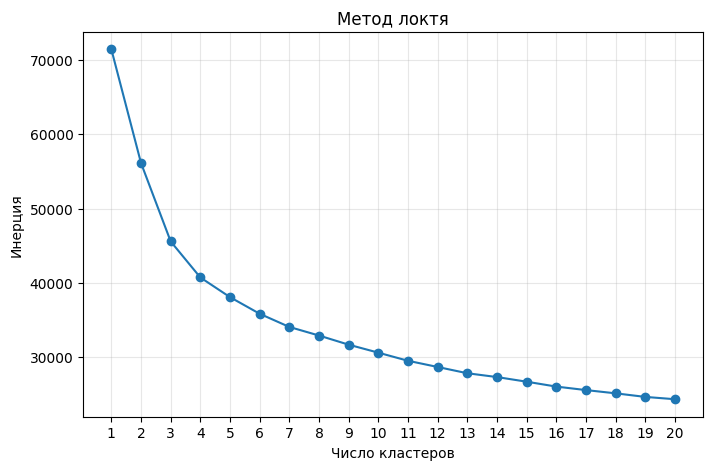

In [52]:
plt.figure(figsize=(8, 5))
plt.plot(ks, inertia, 'o-')
plt.xticks(ks)
plt.xlabel('Число кластеров')
plt.ylabel('Инерция')
plt.title('Метод локтя')
plt.grid(alpha=0.3)
plt.show()

## Вопрос 5

* Постройте модель агломеративного кластеризации с двумя кластерами.
* Сравните полученные результаты с результатами, полученными с помощью алгоритма K-средних, с точки зрения цвета вина.
* Визуализируйте дендрограмму, построенную с помощью агломеративного кластеризации. *Подсказка:* В SciPy есть модуль [`cluster.hierarchy`](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html#module-scipy.cluster.hierarchy), содержащий функции `linkage` и `dendrogram`, необходимые для построения карты связей и отображения полученной дендрограммы.

In [53]:
ag = AgglomerativeClustering(n_clusters=2, linkage='ward')
ag = ag.fit(data[float_columns])
data['agglom'] = ag.fit_predict(data[float_columns])


print('Агломеративная кластеризация:')
print(data.groupby(['color', 'agglom']).size().unstack(fill_value=0), '\n')
print('K-средних:')
print(data.groupby(['color', 'kmeans']).size().unstack(fill_value=0), '\n')
print('Соответствие кластеров kmeans и agglom:')
print(pd.crosstab(data['kmeans'], data['agglom']))

Агломеративная кластеризация:
agglom     0     1
color             
red       21  1578
white   4735   163 

K-средних:
kmeans     0     1
color             
red       24  1575
white   4831    67 

Соответствие кластеров kmeans и agglom:
agglom     0     1
kmeans            
0       4733   122
1         23  1619


Обратите внимание, что распределение по кластерам является произвольным: номера основных кластеров для красного и белого цветов могут не совпадать с приведёнными ниже, а также могут различаться при использовании метода K-средних и агломеративного кластерирования.

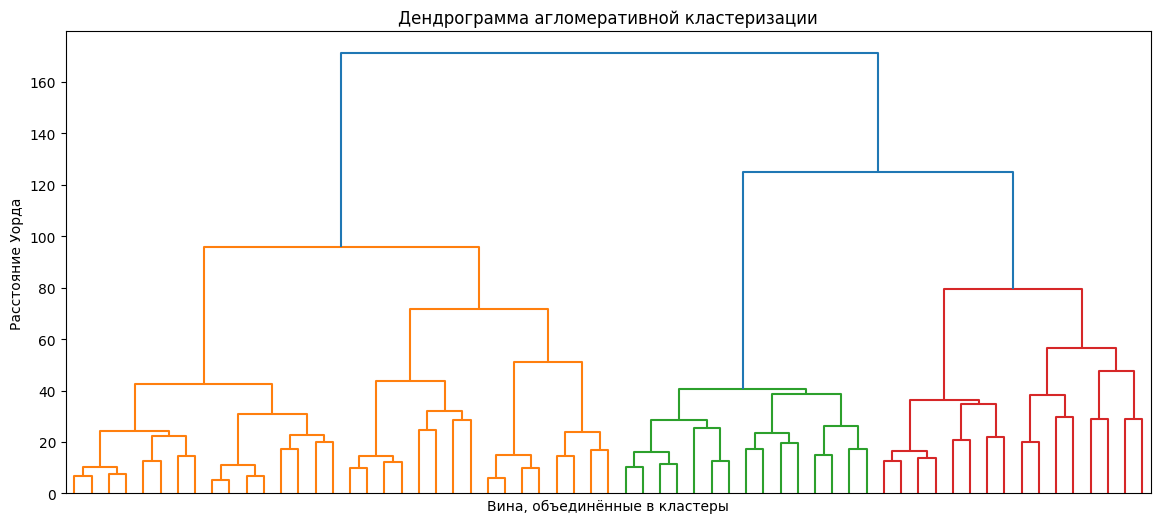

In [54]:
Z = linkage(data[float_columns], method='ward')

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, truncate_mode='level', p=5, show_leaf_counts=True, no_labels=True, ax=ax)
ax.set_title('Дендрограмма агломеративной кластеризации')
ax.set_xlabel('Вина, объединённые в кластеры')
ax.set_ylabel('Расстояние Уорда')
plt.show()

## Вопрос 6

В этом вопросе мы рассмотрим кластеризацию как один из способов инженерии признаков.

* Создайте **бинарную** целевую переменную `y`, указывающую, превышает ли показатель качества значение 7 или нет.
* Создайте переменную `X_with_kmeans` на основе набора данных `data`, удалив из него столбцы «quality», «color» и «agglom». Создайте из него `X_without_kmeans`, удалив столбец «kmeans».
* Для обоих наборов данных с помощью `StratifiedShuffleSplit` с 10 разбиениями обучите 10 классификаторов Random Forest и вычислите среднее значение показателей ROC-AUC.
* Сравните средние значения показателей ROC-AUC для моделей, использующих кластеры k-средних в качестве признака, и для модели, которая их не использует.

In [ ]:
y = (data['quality'] > 7).astype(int)
print(y.value_counts())

X_with_kmeans = data.drop(['quality', 'color', 'agglom'], axis=1)
X_without_kmeans = X_with_kmeans.drop('kmeans', axis=1)
print(X_with_kmeans.shape, X_without_kmeans.shape)

quality
0    6299
1     198
Name: count, dtype: int64
(6497, 12) (6497, 11)


In [56]:
sss = StratifiedShuffleSplit(n_splits=10, test_size=0.3, random_state=42)

def get_avg_score(X, y, model_factory):
    scores = []
    for train_idx, test_idx in sss.split(X, y):
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]
        model = model_factory().fit(X_tr, y_tr)
        scores.append(roc_auc_score(y_te, model.predict_proba(X_te)[:, 1]))
    return np.mean(scores), np.std(scores)

rf = lambda: RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

auc_with, std_with = get_avg_score(X_with_kmeans, y, rf)
auc_without, std_without = get_avg_score(X_without_kmeans, y, rf)

print(f'С кластерами K-средних:  ROC-AUC = {auc_with:.4f} (±{std_with:.4f})')
print(f'Без кластеров K-средних: ROC-AUC = {auc_without:.4f} (±{std_without:.4f})')
print(f'Разница: {auc_with - auc_without:+.4f}')

С кластерами K-средних:  ROC-AUC = 0.8872 (±0.0229)
Без кластеров K-средних: ROC-AUC = 0.8782 (±0.0273)
Разница: +0.0090


Давайте теперь выясним, влияет ли количество кластеров на это улучшение.

* Создайте базовый обучающий набор из `data`, ограничив его столбцами с числами с плавающей запятой.
* Для $n = 1, \ldots, 20$ выполните обучение алгоритма k-средних с $n$ кластерами. Примените к данным кодирование «one-hot» и добавьте их в **базовый** обучающий набор. Не добавляйте их к результатам предыдущей итерации.
* Обучите 10 моделей **логистической регрессии** и вычислите среднее значение показателя ROC-AUC.
* Постройте график средних значений показателя ROC-AUC.

In [57]:
X_base = data[float_columns]

lr = lambda: LogisticRegression(max_iter=1000)

auc_base, _ = get_avg_score(X_base, y, lr)
print(f'Базовый набор без кластеров: ROC-AUC = {auc_base:.4f}')

Базовый набор без кластеров: ROC-AUC = 0.7966


In [58]:
aucs = []
for n in range(1, 21):
    labels = KMeans(n_clusters=n, n_init=10, random_state=42).fit_predict(X_base)
    onehot = pd.get_dummies(pd.Series(labels, index=X_base.index, name='cl'), prefix='cl').astype(float)
    X_n = pd.concat([X_base, onehot], axis=1)
    auc, _ = get_avg_score(X_n, y, lr)
    aucs.append(auc)

pd.DataFrame({'n_clusters': range(1, 21), 'roc_auc': np.round(aucs, 4)})

,n_clusters,roc_auc
0,1,0.7966
1,2,0.7964
2,3,0.7944
3,4,0.7931
4,5,0.7926
5,6,0.7949
6,7,0.7905
7,8,0.8010
8,9,0.7978
9,10,0.7938


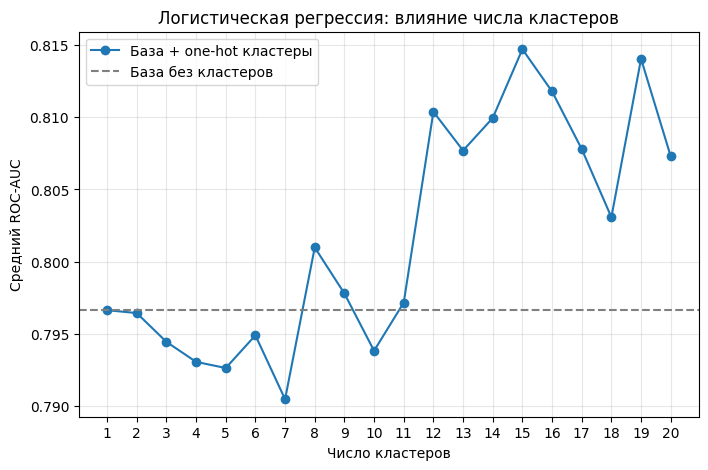

In [59]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 21), aucs, 'o-', label='База + one-hot кластеры')
plt.axhline(auc_base, color='gray', linestyle='--', label='База без кластеров')
plt.xticks(range(1, 21))
plt.xlabel('Число кластеров')
plt.ylabel('Средний ROC-AUC')
plt.title('Логистическая регрессия: влияние числа кластеров')
plt.legend()
plt.grid(alpha=0.3)
plt.show()